# When Outliers Matter: Investigating Gradient-Based Data Selection Under Spurious Correlations

**UCLA CS 260D — Final Project | Fall 2026**

## 1. Dataset Exploration: CelebA

### 1.1 Introduction

Deep learning models can exploit spurious correlations between target labels and unrelated attributes, potentially achieving high average accuracy while performing poorly on underrepresented groups.

Our project investigates whether gradient-based data filtering, particularly an EPIC-inspired method, disproportionately removes informative minority examples and consequently affects worst-group generalization.

We use the CelebA dataset, a large-scale facial attribute benchmark containing 202,599 aligned face images with 40 binary attributes.

### 1.2 Classification Task

Our primary prediction target is **Blond_Hair**, while **Male** serves as the spurious attribute. This corresponds to an established group-robustness benchmark where the distribution of hair color varies across the dataset's annotated demographic groups.

We define four groups using the combinations of these two binary attributes:

| Group | Blond_Hair | Male |
|---|---|---|
| 0 | No | No |
| 1 | No | Yes |
| 2 | Yes | No |
| 3 | Yes | Yes |

Our primary evaluation metric is **worst-group accuracy**, supplemented by average accuracy, per-group accuracy, and group-specific sample retention rates.

### 1.3 Dataset Exploration Objectives

1. Verify the CelebA image files, labels, and official dataset partitions.
2. Calculate class distributions and the representation of all four groups.
3. Visualize representative images from each group.
4. Identify minority-group imbalances that could influence gradient-based filtering.
5. Establish a reproducible dataset configuration for subsequent ERM, EPIC, JTT, and random-filtering experiments.

The exploratory analysis will establish the dataset characteristics before any model training or filtering is performed.

### 1.4 Loading CelebA Attributes and Dataset Partitions

We load the official CelebA attribute annotations and dataset partitions to construct a reproducible binary classification benchmark.

Our target variable is **Blond_Hair**, and the spurious attribute is **Male**, as defined by CelebA's original annotations. Attribute values are encoded as `-1` (absent) and `1` (present), which we convert to binary labels `0` and `1`.

We preserve the official training, validation, and test partitions without reshuffling or modifying their membership.

Each sample is assigned to one of four groups based on its combination of target and spurious attributes. We then calculate group sizes and percentages for each split, allowing us to identify underrepresented groups and establish the basis for worst-group evaluation.

**Objective:** Verify annotation consistency and quantify group imbalance before any model training or data filtering.

In [1]:

# ============================================================
# 1.4 Load CelebA attributes and official dataset partitions
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Define dataset paths
# ------------------------------------------------------------

DATA_ROOT = Path("data/celeba")

IMAGE_DIR = DATA_ROOT / "img_align_celeba"
ATTRIBUTE_FILE = DATA_ROOT / "list_attr_celeba.txt"
PARTITION_FILE = DATA_ROOT / "list_eval_partition.txt"

# Verify that all required files are available.
assert IMAGE_DIR.is_dir(), "Image directory not found."
assert ATTRIBUTE_FILE.is_file(), "Attribute file not found."
assert PARTITION_FILE.is_file(), "Partition file not found."

# ------------------------------------------------------------
# 2. Load attribute annotations
# ------------------------------------------------------------

# CelebA attribute file:
# Line 1: number of examples
# Line 2: names of 40 facial attributes
# Remaining lines: filename followed by attribute values
attributes = pd.read_csv(
    ATTRIBUTE_FILE,
    sep=r"\s+",
    skiprows=2,
    header=None,
    names=[
        "filename",
        *ATTRIBUTE_FILE.read_text().splitlines()[1].split()
    ],
)

# Select target and spurious attributes.
attributes = attributes[
    ["filename", "Blond_Hair", "Male"]
].copy()

# Convert original {-1, 1} annotations into {0, 1}.
for column in ["Blond_Hair", "Male"]:
    attributes[column] = (
        attributes[column].astype(int) == 1
    ).astype(int)

# ------------------------------------------------------------
# 3. Load official dataset partitions
# ------------------------------------------------------------

# Split identifiers:
# 0 = Training
# 1 = Validation
# 2 = Test
partitions = pd.read_csv(
    PARTITION_FILE,
    sep=r"\s+",
    header=None,
    names=["filename", "split"],
)

# Join using filenames to preserve correct label alignment.
df = attributes.merge(
    partitions,
    on="filename",
    how="inner",
    validate="one_to_one",
)

# ------------------------------------------------------------
# 4. Assign four class-spurious groups
# ------------------------------------------------------------

# Group encoding:
# 0: Non-blond, Non-male
# 1: Non-blond, Male
# 2: Blond, Non-male
# 3: Blond, Male
df["group"] = df["Blond_Hair"] * 2 + df["Male"]

# ------------------------------------------------------------
# 5. Validate dataset structure
# ------------------------------------------------------------

assert len(df) == 202599, "Unexpected number of samples."
assert df["filename"].is_unique
assert df["split"].isin([0, 1, 2]).all()

print("=" * 60)
print("CelebA — Dataset Summary")
print("=" * 60)

print(f"Total annotated images: {len(df):,}")
print(f"Image directory: {IMAGE_DIR}")

split_names = {
    0: "Training",
    1: "Validation",
    2: "Test",
}

for split_id, split_name in split_names.items():
    subset = df[df["split"] == split_id]

    print(f"\n{split_name}: {len(subset):,} examples")
    print("-" * 45)

    for group_id in range(4):
        count = int((subset["group"] == group_id).sum())
        percentage = count / len(subset) * 100

        print(
            f"Group {group_id}: "
            f"{count:,} samples ({percentage:.2f}%)"
        )

print("\nDataset annotations loaded successfully!")


CelebA — Dataset Summary
Total annotated images: 202,599
Image directory: data/celeba/img_align_celeba

Training: 162,770 examples
---------------------------------------------
Group 0: 71,629 samples (44.01%)
Group 1: 66,874 samples (41.08%)
Group 2: 22,880 samples (14.06%)
Group 3: 1,387 samples (0.85%)

Validation: 19,867 examples
---------------------------------------------
Group 0: 8,535 samples (42.96%)
Group 1: 8,276 samples (41.66%)
Group 2: 2,874 samples (14.47%)
Group 3: 182 samples (0.92%)

Test: 19,962 examples
---------------------------------------------
Group 0: 9,767 samples (48.93%)
Group 1: 7,535 samples (37.75%)
Group 2: 2,480 samples (12.42%)
Group 3: 180 samples (0.90%)

Dataset annotations loaded successfully!


### 1.5 Visualization of CelebA Attribute Groups

To examine the relationship between the classification target and the spurious attribute, we visualize representative training images from each of the four groups defined by **Blond_Hair** and **Male**.

The dataset shows substantial group imbalance, particularly for Group 3 (Blond_Hair = 1, Male = 1), which represents only 0.85% of the training set.

We randomly sample five images from each group using a fixed random seed to ensure reproducibility. These examples help illustrate the visual diversity and attribute combinations present in the dataset.

**Objective:** Inspect the four class–attribute groups and establish a visual reference for investigating whether gradient-based filtering disproportionately removes rare but informative training examples.

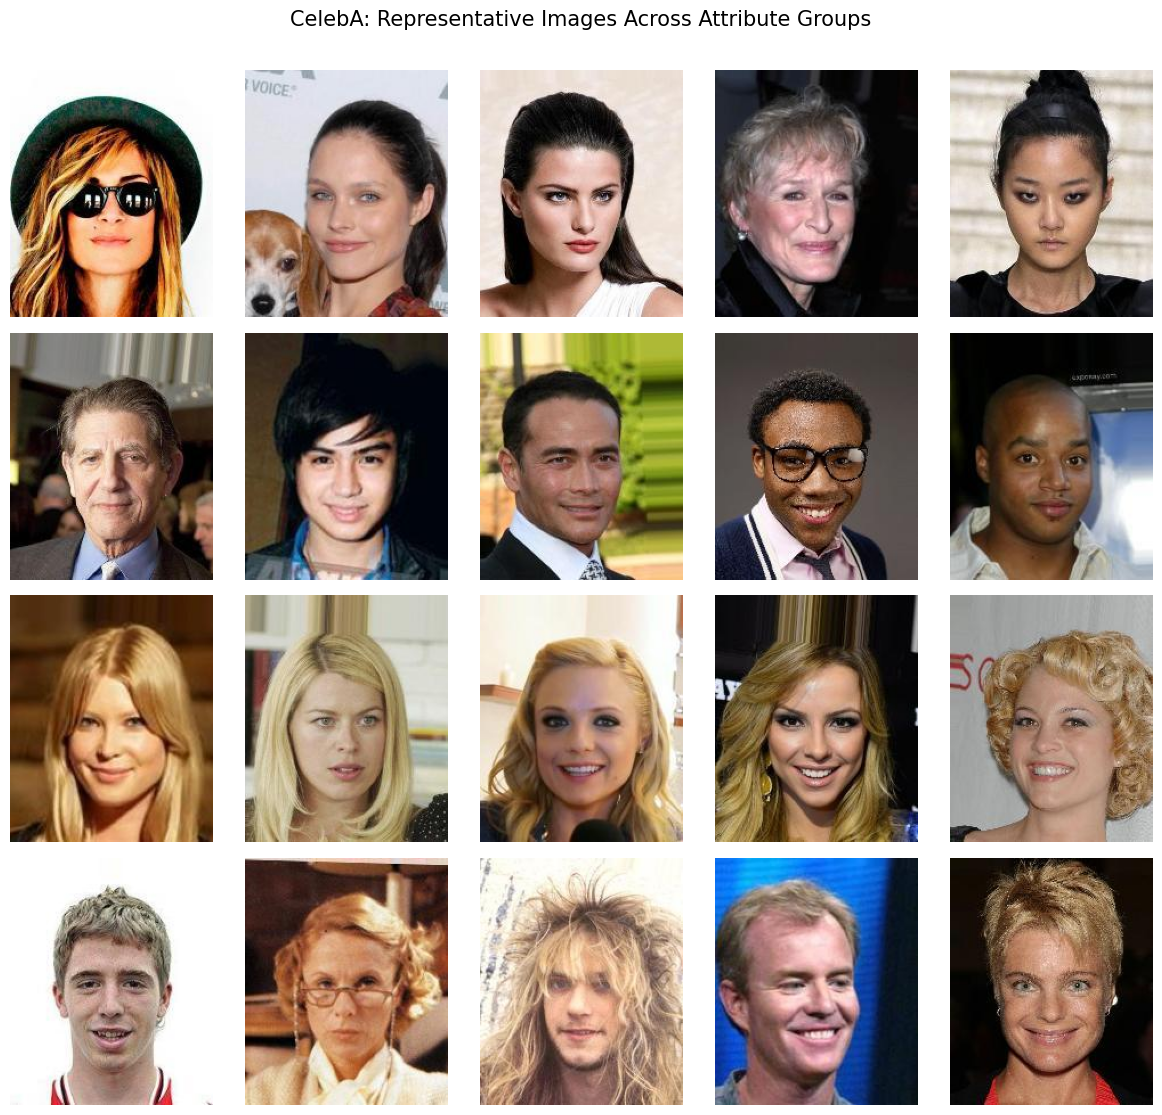

Figure saved to: results/figures/celeba_group_examples.png


In [2]:

# ============================================================
# 1.5 Visualize representative CelebA training examples
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Visualization configuration
# ------------------------------------------------------------

RANDOM_SEED = 42
SAMPLES_PER_GROUP = 5

rng = np.random.default_rng(RANDOM_SEED)

# Use training examples only.
train_df = df[df["split"] == 0]

group_names = {
    0: "Non-blond / Non-male",
    1: "Non-blond / Male",
    2: "Blond / Non-male",
    3: "Blond / Male",
}

# ------------------------------------------------------------
# 2. Sample and display images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    SAMPLES_PER_GROUP,
    figsize=(12, 11),
)

for group_id in range(4):

    group_df = train_df[
        train_df["group"] == group_id
    ]

    sampled = group_df.sample(
        n=SAMPLES_PER_GROUP,
        random_state=RANDOM_SEED,
    )

    for col, (_, row) in enumerate(sampled.iterrows()):

        image_path = IMAGE_DIR / row["filename"]

        # Load and convert to RGB.
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            axes[group_id, col].imshow(image)

        axes[group_id, col].axis("off")

    # Label each row.
    axes[group_id, 0].set_ylabel(
        f"Group {group_id}\n{group_names[group_id]}",
        fontsize=10,
        rotation=0,
        labelpad=95,
        va="center",
    )

plt.suptitle(
    "CelebA: Representative Images Across Attribute Groups",
    fontsize=15,
    y=1.01,
)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save report-quality figure
# ------------------------------------------------------------

FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

save_path = FIGURE_DIR / "celeba_group_examples.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {save_path}")


### 1.6 Analysis of Attribute-Group Imbalance

We analyze the distribution of the four CelebA attribute groups across the official training, validation, and test partitions.

The training dataset contains 162,770 examples, but group representation is highly uneven. In particular, Group 3 (Blond_Hair = 1, Male = 1) contains only 1,387 training examples, representing approximately 0.85% of the training set.

This imbalance creates an important challenge for gradient-based data selection: rare examples may have different gradient representations from the dominant training population.

We visualize the group proportions across all three dataset partitions to examine whether the imbalance persists during evaluation.

**Research significance:** The rarest group provides an important test case for investigating whether EPIC-inspired filtering preserves informative minority examples or disproportionately removes them.

Group rarity alone does not establish gradient-space isolation. We will investigate that relationship experimentally.

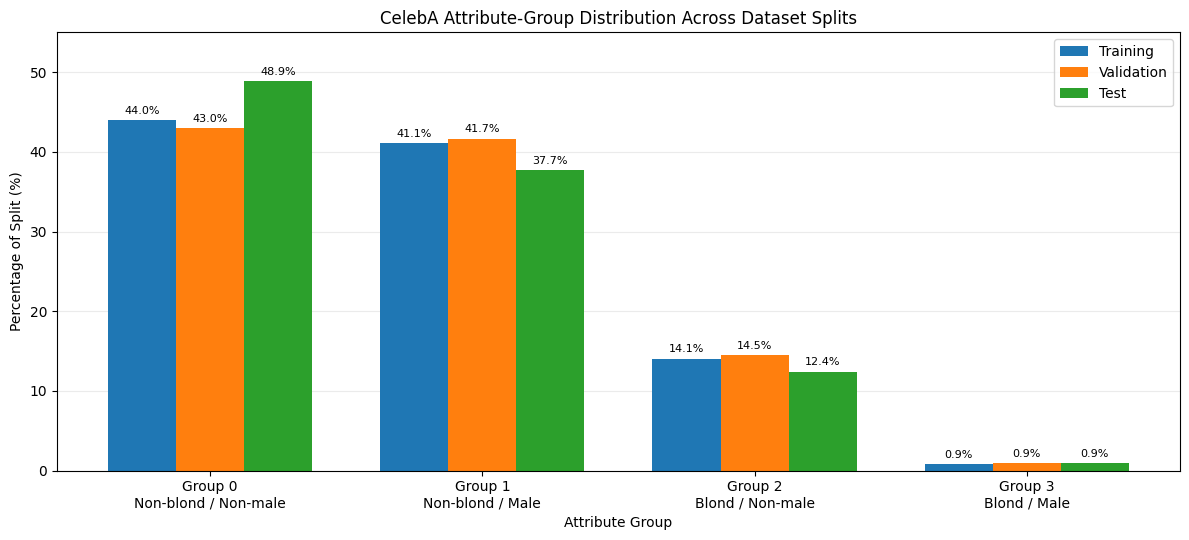

Figure saved to: results/figures/celeba_group_distribution.png


In [3]:

# ============================================================
# 1.6 Visualize CelebA group distributions across splits
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Calculate group proportions for each split
# ------------------------------------------------------------

split_names = {
    0: "Training",
    1: "Validation",
    2: "Test",
}

group_names = [
    "Group 0\nNon-blond / Non-male",
    "Group 1\nNon-blond / Male",
    "Group 2\nBlond / Non-male",
    "Group 3\nBlond / Male",
]

group_percentages = {}

for split_id, name in split_names.items():
    subset = df[df["split"] == split_id]

    percentages = [
        (subset["group"] == group_id).mean() * 100
        for group_id in range(4)
    ]

    group_percentages[name] = percentages

# ------------------------------------------------------------
# 2. Plot grouped bar chart
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5.5))

x = np.arange(4)
width = 0.25

for i, (name, values) in enumerate(
    group_percentages.items()
):
    offset = (i - 1) * width

    bars = ax.bar(
        x + offset,
        values,
        width,
        label=name,
    )

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=8,
    )

ax.set_title(
    "CelebA Attribute-Group Distribution Across Dataset Splits"
)
ax.set_xlabel("Attribute Group")
ax.set_ylabel("Percentage of Split (%)")

ax.set_xticks(x)
ax.set_xticklabels(group_names)

ax.set_ylim(0, 55)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure for the research report
# ------------------------------------------------------------

FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

save_path = FIGURE_DIR / "celeba_group_distribution.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {save_path}")


### 1.7 Dataset Preparation and Reproducibility

We consolidate the CelebA annotations into a single metadata table containing each image's filename, binary classification target, spurious attribute, group identifier, and official dataset split.

The official CelebA partitions are preserved to prevent data leakage and ensure consistent comparisons across all training methods.

We export the processed metadata as a CSV file, allowing subsequent experiments to use identical labels and group assignments without repeatedly parsing the original annotation files.

Group annotations will be used for evaluation and analysis, while standard ERM and EPIC-inspired filtering will not use group membership to determine training weights or filtering decisions.

**Outcome:** A reproducible dataset configuration shared across all experiments.

In [4]:

# ============================================================
# 1.7 Export reproducible CelebA dataset metadata
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare output directory
# ------------------------------------------------------------

PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Organize dataset metadata
# ------------------------------------------------------------

metadata = df[
    ["filename", "Blond_Hair", "Male", "group", "split"]
].copy()

metadata = metadata.rename(
    columns={
        "Blond_Hair": "label",
        "Male": "spurious_attribute",
    }
)

# Sort to ensure deterministic row ordering.
metadata = metadata.sort_values(
    "filename"
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Validate metadata
# ------------------------------------------------------------

assert len(metadata) == 202599
assert metadata["filename"].is_unique
assert metadata["label"].isin([0, 1]).all()
assert metadata["spurious_attribute"].isin([0, 1]).all()
assert metadata["group"].isin([0, 1, 2, 3]).all()
assert metadata["split"].isin([0, 1, 2]).all()

assert (
    metadata["group"]
    == metadata["label"] * 2
    + metadata["spurious_attribute"]
).all()

# ------------------------------------------------------------
# 4. Export metadata
# ------------------------------------------------------------

save_path = PROCESSED_DIR / "celeba_metadata.csv"

metadata.to_csv(
    save_path,
    index=False,
)

print("=" * 55)
print("CelebA Dataset Preparation")
print("=" * 55)
print(f"Total examples: {len(metadata):,}")
print(f"Metadata saved to: {save_path}")

print("\nSplit distribution:")
print(
    metadata["split"]
    .value_counts()
    .sort_index()
)

print("\nMetadata preview:")
print(metadata.head())

print("\nDataset preparation completed successfully!")


CelebA Dataset Preparation
Total examples: 202,599
Metadata saved to: data/processed/celeba_metadata.csv

Split distribution:
split
0    162770
1     19867
2     19962
Name: count, dtype: int64

Metadata preview:
     filename  label  spurious_attribute  group  split
0  000001.jpg      0                   0      0      0
1  000002.jpg      0                   0      0      0
2  000003.jpg      0                   1      1      0
3  000004.jpg      0                   0      0      0
4  000005.jpg      0                   0      0      0

Dataset preparation completed successfully!
